# S4 — Generation of the synthetic sets

**Goal:** build fixed, reproducible synthetic datasets from the two S3 models, to be used in S5 (augmentation and TSTR).

| Rule | How |
|---|---|
| **Fixed and reproducible** | seed `2026` (`configs/generate.yaml`); z is drawn on CPU, so the same seed always gives the same images (checked below) |
| **Kept apart from the real data** | each set is saved in its own file `data/synthetic/<model>_n800_seed2026.npz`, flagged `synthetic=True` (not committed: `data/` is ignored by Git) |
| **Training set only** (brief) | validation and test always come from `load_split()`; a check below proves that no synthetic image is in val or test |
| **Marked as synthetic** | every synthetic image shown outside the training arrays gets a red **SYNTHETIC** banner (`watermark()`); the training arrays themselves stay clean |

**Models:** CVAE β = 1 (`checkpoints/cvae.pt`) and cGAN after 100 epochs (`checkpoints/cgan_G.pt`).
**Size:** 800 images per class and per model (7 × 800 = 5 600 per model). 800 covers the largest amount tested in S5 (+800 df images).

> **Runs on the laptop, with the `.venv` kernel** (no GPU needed, about 1 minute). It needs the S3 checkpoints in `checkpoints/`: if they are missing, extract them first with `python -m src.extract_results notebooks/03a_cvae.ipynb` (and `03b_cgan.ipynb`).

In [1]:
# --- Setup (LOCAL run with the .venv kernel, not Colab) ---
import os, sys
from pathlib import Path

if "google.colab" in sys.modules or Path("/content").exists():
    raise RuntimeError(
        "This notebook must run on your laptop, not on Colab: the S3 checkpoints (cvae.pt, cgan_G.pt) "
        "are on the laptop. In VS Code: Select Kernel -> Python Environments -> .venv, then Run All.")

if Path.cwd().name == "notebooks":
    os.chdir("..")                      # run from the repository root
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
print("Project root:", Path.cwd())

Project root: c:\Users\DELL\Downloads\genia_visual\mini_project


In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_split, sample_per_class, to_tensor, NUM_CLASSES, SHORT_NAMES
from src.generate import (load_generator, generate_set, save_synthetic, load_synthetic,
                          assert_real_only, watermark)
from src.viz import plot_class_grid
from src.utils import load_config, ensure_dirs, RESULTS_DIR

cfg = load_config("generate")
ensure_dirs()
print(cfg)

{'models': ['cvae', 'cgan'], 'n_per_class': 800, 'seed': 2026, 'z_dim': 64}


## 1. Generate and save the two synthetic sets

In [3]:
paths, syn = {}, {}
for name in cfg["models"]:
    t0 = time.time()
    generator = load_generator(name, cfg["z_dim"])
    images, labels = generate_set(generator, cfg["n_per_class"], seed=cfg["seed"])
    paths[name] = save_synthetic(images, labels, name, cfg["n_per_class"], cfg["seed"])
    syn[name] = load_synthetic(paths[name])           # reload from disk: what S5 will use
    print(f"{name}: {images.shape} {images.dtype} -> {paths[name].relative_to(Path.cwd())} "
          f"({paths[name].stat().st_size / 1e6:.1f} MB, {time.time() - t0:.0f}s)")

cvae: (5600, 64, 64, 3) uint8 -> data\synthetic\cvae_n800_seed2026.npz (51.7 MB, 12s)
cgan: (5600, 64, 64, 3) uint8 -> data\synthetic\cgan_n800_seed2026.npz (62.7 MB, 12s)


## 2. Size of the sets compared with the real training data

In [4]:
train_x, train_y = load_split("train")
table = pd.DataFrame({name: np.bincount(y, minlength=NUM_CLASSES) for name, (x, y) in syn.items()},
                     index=SHORT_NAMES)
table.insert(0, "real train", np.bincount(train_y, minlength=NUM_CLASSES))
table.loc["total"] = table.sum()
table.to_csv(RESULTS_DIR / "s4_synthetic_sets.csv")
table

,real train,cvae,cgan
akiec,228,800,800
bcc,359,800,800
bkl,769,800,800
df,80,800,800
mel,779,800,800
nv,4693,800,800
vasc,99,800,800
total,7007,5600,5600


## 3. Reproducibility: same seed → same images

Each set is generated a second time from scratch with the same seed and compared pixel by pixel with the saved file. This is what makes the sets "fixed": S5 can rebuild them at any time from the checkpoints.

In [5]:
for name in cfg["models"]:
    again, _ = generate_set(load_generator(name, cfg["z_dim"]), cfg["n_per_class"], seed=cfg["seed"])
    saved = syn[name][0]
    diff = np.abs(again.astype(int) - saved.astype(int)).max()
    print(f"{name}: regenerated with seed {cfg['seed']} -> identical: {np.array_equal(again, saved)} "
          f"(max pixel difference {diff})")

cvae: regenerated with seed 2026 -> identical: True (max pixel difference 0)
cgan: regenerated with seed 2026 -> identical: True (max pixel difference 0)


## 4. Leak check: validation and test stay 100 % real

Validation and test are always loaded with `load_split()`, never from `data/synthetic/`. This check confirms it: no synthetic image (exact pixel match) appears in val or test.

In [6]:
val_x, _ = load_split("val")
test_x, _ = load_split("test")
for name, (x, _) in syn.items():
    assert_real_only(val_x, x, f"val (vs {name})")
    assert_real_only(test_x, x, f"test (vs {name})")

OK: val (vs cvae) contains no synthetic image (1003 images checked)
OK: test (vs cvae) contains no synthetic image (2005 images checked)
OK: val (vs cgan) contains no synthetic image (1003 images checked)
OK: test (vs cgan) contains no synthetic image (2005 images checked)


## 5. Real vs CVAE vs cGAN (first 8 images of each class in the saved sets)

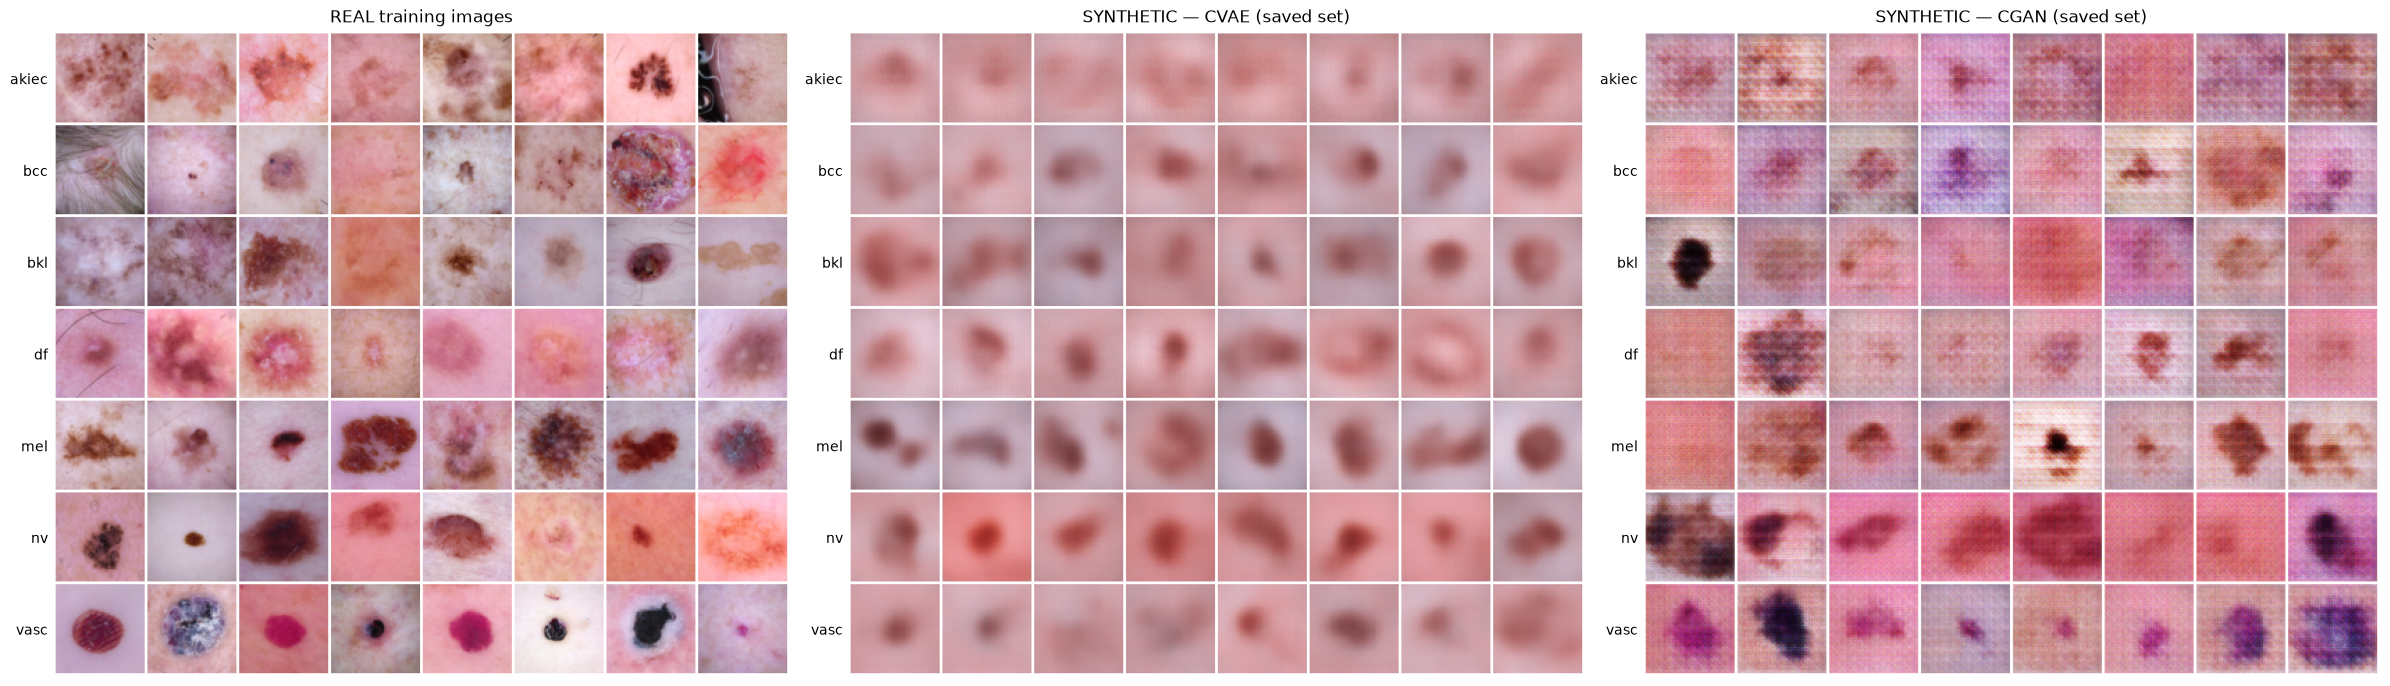

In [7]:
real, _ = sample_per_class(train_x, train_y, 8, seed=0)
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
plot_class_grid(real, 8, ax=axes[0], title="REAL training images")
for ax, name in zip(axes[1:], cfg["models"]):
    x, y = syn[name]
    idx = np.concatenate([np.flatnonzero(y == c)[:8] for c in range(NUM_CLASSES)])
    plot_class_grid(to_tensor(x[idx]), 8, ax=ax, title=f"SYNTHETIC — {name.upper()} (saved set)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s4_real_cvae_cgan.png", dpi=100, bbox_inches="tight")
plt.show()

## 6. Watermark: how synthetic images are shown

Every synthetic image displayed or exported outside the training arrays (report, demo, slides) carries this banner, so it can never be mistaken for a real patient image.

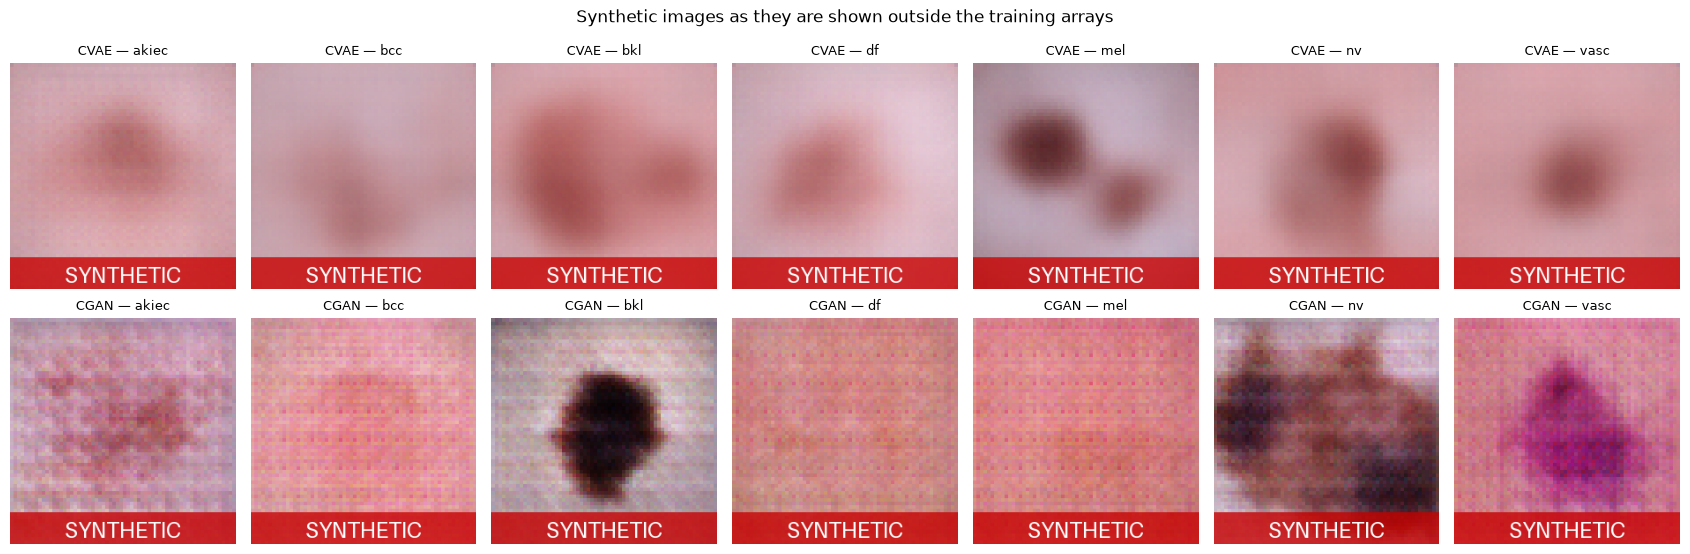

In [8]:
fig, axes = plt.subplots(len(cfg["models"]), NUM_CLASSES, figsize=(17, 2.9 * len(cfg["models"])))
for row, name in enumerate(cfg["models"]):
    x, y = syn[name]
    for c in range(NUM_CLASSES):
        ax = axes[row, c]
        ax.imshow(watermark(x[np.flatnonzero(y == c)[0]]))
        ax.set_title(f"{name.upper()} — {SHORT_NAMES[c]}", fontsize=9)
        ax.axis("off")
fig.suptitle("Synthetic images as they are shown outside the training arrays")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s4_watermarked_examples.png", dpi=100, bbox_inches="tight")
plt.show()

## 7. Interpretation (to complete after running)

- **Sets:** do both files contain 5 600 images (800 per class)? For **df**, 800 synthetic images is 10× the 80 real ones: S5 will test how many are actually useful (+100 / +200 / +400 / +800).
- **Reproducibility:** are both sets identical when regenerated?
- **Leak check:** do val and test contain no synthetic image?
- **Visual comparison:** CVAE images are smooth and blurry; cGAN images are sharper, with more colour and shape variety but a faint grid pattern (S3 results).

## Conclusion of S4
- Synthetic sets: `data/synthetic/cvae_n800_seed2026.npz` and `data/synthetic/cgan_n800_seed2026.npz` (not committed, regenerated in about 1 minute with this notebook).
- Figures and table: `results/s4_*`.
- Next: **S5**, evaluation (quality, memorization, usefulness for the classifier, TSTR).